In [2]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from scipy.signal import fftconvolve
from scipy.stats import gamma
import nibabel as nib

DATA  = Path('/content/drive/MyDrive/Brain_alignment/lpp_data')
FUNC  = DATA / 'sub-EN057/func'
ANNOT = DATA / 'annotation/EN'

RUN_SECTION_MAP = {15: 1, 16: 2, 17: 3, 18: 4}
TR = 2.0
CONTEXT_SIZES = [1, 5, 20, 50, 100, -1]
CTX_LABELS    = ['1', '5', '20', '50', '100', 'full']

Mounted at /content/drive


In [ ]:
word_info = pd.read_csv(ANNOT / 'lppEN_word_information.csv')
dep_info  = pd.read_csv(ANNOT / 'lppEN_dependency.csv', header=None,
                         names=['relation'])

# Parse dependency file: extract dependent word index
# Format: "nsubj(saw-8, i-3)" — we want the index of the dependent
def parse_dep_index(s):
    try:
        dep_part = s.split(',')[-1].strip().rstrip(')')
        idx = int(dep_part.split('-')[-1]) - 1  # 1-indexed → 0-indexed
        return idx
    except:
        return -1

dep_info['word_idx'] = dep_info['relation'].apply(parse_dep_index)

# Add dependency distance to word_info
# Distance = |head_position - dependent_position|
def parse_head_index(s):
    try:
        head_part = s.split('(')[1].split(',')[0].strip()
        idx = int(head_part.split('-')[-1]) - 1
        return idx
    except:
        return -1

dep_info['head_idx'] = dep_info['relation'].apply(parse_head_index)
dep_info['dep_distance'] = abs(dep_info['head_idx'] - dep_info['word_idx'])

# Map dependency distance onto word_info by word index
word_info['dep_distance'] = np.nan
for _, row in dep_info.iterrows():
    idx = row['word_idx']
    if 0 <= idx < len(word_info):
        word_info.loc[idx, 'dep_distance'] = row['dep_distance']

print(word_info[['word', 'pos', 'dep_distance']].head(10))
print(f"\nPOS distribution:\n{word_info['pos'].value_counts()}")

    word   pos  dep_distance
0   once   ADV           1.0
1   when   ADV           2.0
2      i  PRON           3.0
3    was   AUX           4.0
4    six   NUM           5.0
5  years  NOUN           6.0
6    old   ADJ           7.0
7      i  PRON           8.0
8    saw  VERB           9.0
9      a   DET          10.0

POS distribution:
pos
VERB     2341
NOUN     2313
PRON     2120
DET      2081
ADP      1294
AUX      1130
ADV      1114
ADJ      1013
CCONJ     509
PART      463
SCONJ     406
NUM       281
PROPN     232
INTJ       77
X           2
Name: count, dtype: int64


In [ ]:
# Load BOLD
bold_stack = []
n_trs_per_run = {}
for run in RUN_SECTION_MAP:
    img  = nib.load(str(FUNC / f'sub-EN057_task-lppEN_run-{run}_echo-1_bold.nii.gz'))
    n_trs_per_run[run] = img.shape[3]
    bold_stack.append(img.get_fdata().reshape(-1, img.shape[3]).T)

bold_all = np.concatenate(bold_stack, axis=0)
mask     = bold_all.std(axis=0) > 0
bold_all = bold_all[:, mask]
print(f"BOLD: {bold_all.shape}")

# Load word-level GPT-2 embeddings saved in Day 3
all_embeddings = {}
for run in RUN_SECTION_MAP:
    f = np.load(DATA / f'gpt2_word_embeddings_run{run}.npz')
    all_embeddings[run] = {int(k) if k != 'full' else -1: f[k] for k in f.files}
print("Embeddings loaded.")

BOLD: (1239, 129385)
Embeddings loaded.


In [ ]:
def hrf_kernel(tr=2.0, n_trs=20):
    t = np.arange(0, n_trs * tr, tr)
    h = gamma.pdf(t, 6) - 0.35 * gamma.pdf(t, 16)
    return h / h.max()

def convolve_hrf(X, tr=2.0):
    h   = hrf_kernel(tr=tr)
    out = np.zeros_like(X)
    for i in range(X.shape[1]):
        conv = fftconvolve(X[:, i], h, mode='full')
        out[:, i] = conv[:X.shape[0]]
    return out

def encode_model(X, Y, n_components=50, n_splits=5):
    X_pca = PCA(n_components=n_components).fit_transform(
                StandardScaler().fit_transform(X))
    kf = KFold(n_splits=n_splits, shuffle=False)
    r2_folds = []
    for tr_idx, te_idx in kf.split(X_pca):
        ridge = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100, 1000])
        ridge.fit(X_pca[tr_idx], Y[tr_idx])
        r2_folds.append(r2_score(Y[te_idx], ridge.predict(X_pca[te_idx]),
                                  multioutput='raw_values'))
    return np.mean(r2_folds, axis=0)

def words_to_trs_subset(emb, tr_indices, n_trs, subset_mask, hidden=1024):
    """Average embeddings within TR, using only words in subset_mask."""
    mat    = np.zeros((n_trs, hidden))
    counts = np.zeros(n_trs)
    for i, tr_idx in enumerate(tr_indices):
        if subset_mask[i]:
            mat[tr_idx]    += emb[i]
            counts[tr_idx] += 1
    mask = counts > 0
    mat[mask] /= counts[mask, None]
    return mat, mask

In [ ]:
# Build per-run alignments
alignments = {}
for run, sec in RUN_SECTION_MAP.items():
    sec_words = word_info[word_info['section'] == sec].copy()
    sec_words['word'] = sec_words['word'].fillna('').astype(str)
    n_trs = n_trs_per_run[run]
    sec_words['TR_index'] = (sec_words['onset'] / TR).astype(int).clip(upper=n_trs-1)
    alignments[run] = sec_words

# Focus on full context condition for linguistic breakdown
CTX = -1  # full context

POS_GROUPS = {
    'NOUN': ['NOUN', 'PROPN'],
    'VERB': ['VERB', 'AUX'],
    'ADJ':  ['ADJ'],
    'FUNC': ['DET', 'PREP', 'ADP', 'CCONJ', 'SCONJ', 'PRON', 'PART'],
}

pos_r2 = {}
for group_name, pos_tags in POS_GROUPS.items():
    # Build TR matrix using only words of this POS
    tr_mats = []
    for run in RUN_SECTION_MAP:
        aln     = alignments[run]
        emb     = all_embeddings[run][CTX]
        submask = aln['pos'].isin(pos_tags).values
        mat, _  = words_to_trs_subset(emb, aln['TR_index'].values,
                                       n_trs_per_run[run], submask)
        tr_mats.append(mat)

    X_pos = np.concatenate(tr_mats, axis=0)
    X_pos = convolve_hrf(X_pos)

    print(f"Running POS={group_name}...")
    r2 = encode_model(X_pos, bold_all)
    pos_r2[group_name] = r2
    print(f"  mean R²={r2[r2>0].mean():.4f}, positive voxels={( r2>0).sum()}")

Running POS=NOUN...
  mean R²=0.0411, positive voxels=55
Running POS=VERB...
  mean R²=0.0412, positive voxels=57
Running POS=ADJ...
  mean R²=0.0134, positive voxels=12
Running POS=FUNC...
  mean R²=0.0553, positive voxels=70


In [ ]:
# Split words into low vs high dependency distance
dep_r2 = {}
for label, condition in [('low_dep', lambda d: d <= 2),
                          ('high_dep', lambda d: d > 2)]:
    tr_mats = []
    for run in RUN_SECTION_MAP:
        aln     = alignments[run]
        emb     = all_embeddings[run][CTX]
        submask = aln['dep_distance'].apply(
                    lambda d: condition(d) if pd.notna(d) else False).values
        mat, _  = words_to_trs_subset(emb, aln['TR_index'].values,
                                       n_trs_per_run[run], submask)
        tr_mats.append(mat)

    X_dep = convolve_hrf(np.concatenate(tr_mats, axis=0))
    print(f"Running {label}...")
    r2 = encode_model(X_dep, bold_all)
    dep_r2[label] = r2
    print(f"  mean R²={r2[r2>0].mean():.4f}, positive voxels={(r2>0).sum()}")

Running low_dep...


/tmp/ipykernel_494/890515752.py:19: RuntimeWarning: Mean of empty slice.
  print(f"  mean R²={r2[r2>0].mean():.4f}, positive voxels={(r2>0).sum()}")
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  mean R²=nan, positive voxels=0
Running high_dep...
  mean R²=nan, positive voxels=0


/tmp/ipykernel_494/890515752.py:19: RuntimeWarning: Mean of empty slice.
  print(f"  mean R²={r2[r2>0].mean():.4f}, positive voxels={(r2>0).sum()}")
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [ ]:
dep_raw = pd.read_csv(ANNOT / 'lppEN_dependency.csv', header=None, names=['relation'])
print(dep_raw.shape)
print(dep_raw.head(10))

(15865, 1)
                   relation
advmod(old-7        once-1)
advmod(old-7        when-2)
nsubj(old-7            i-3)
cop(old-7            was-4)
nummod(years-6       six-5)
nmod:npmod(old-7   years-6)
advcl(saw-9          old-7)
nsubj(saw-9            i-8)
root(ROOT-0          saw-9)
det(picture-12        a-10)


In [ ]:
# Check what the parsed indices look like
dep_raw['head_idx'] = dep_raw['relation'].apply(parse_head_index)
dep_raw['word_idx'] = dep_raw['relation'].apply(parse_dep_index)
dep_raw['dep_distance'] = abs(dep_raw['head_idx'] - dep_raw['word_idx'])
print(dep_raw.head(10))
print(f"\ndep_distance stats: {dep_raw['dep_distance'].describe()}")

                   relation  head_idx  word_idx  dep_distance
advmod(old-7        once-1)        -1         0             1
advmod(old-7        when-2)        -1         1             2
nsubj(old-7            i-3)        -1         2             3
cop(old-7            was-4)        -1         3             4
nummod(years-6       six-5)        -1         4             5
nmod:npmod(old-7   years-6)        -1         5             6
advcl(saw-9          old-7)        -1         6             7
nsubj(saw-9            i-8)        -1         7             8
root(ROOT-0          saw-9)        -1         8             9
det(picture-12        a-10)        -1         9            10

dep_distance stats: count    15865.000000
mean         8.004286
std          6.799501
min          1.000000
25%          3.000000
50%          6.000000
75%         11.000000
max         49.000000
Name: dep_distance, dtype: float64


In [ ]:
# Check how many words in section 1 got a dep_distance assigned
sec1 = word_info[word_info['section'] == 1].copy()
print(f"Section 1 words: {len(sec1)}")
print(f"With dep_distance: {sec1['dep_distance'].notna().sum()}")
print(sec1[['word', 'dep_distance']].head(20))

Section 1 words: 1517
With dep_distance: 49
           word  dep_distance
0          once           1.0
1          when           2.0
2             i           3.0
3           was           4.0
4           six           5.0
5         years           6.0
6           old           7.0
7             i           8.0
8           saw           9.0
9             a          10.0
10  magnificent          11.0
11      picture          12.0
12           in          13.0
13            a          14.0
14         book          15.0
15        about          16.0
16          the          17.0
17     primeval          18.0
18       forest          19.0
19       called          20.0


In [ ]:
import re

def parse_dependency(relation_str):
    """Parse 'reltype(head-idx  dep-idx)' with variable whitespace."""
    try:
        # Extract content inside parentheses
        inner = re.search(r'\((.+)\)', relation_str).group(1)
        parts = inner.strip().split()
        head_part = parts[0].rstrip(',')
        dep_part  = parts[-1].rstrip(')')
        head_idx  = int(head_part.split('-')[-1]) - 1  # 1-indexed → 0
        dep_idx   = int(dep_part.split('-')[-1]) - 1
        dist      = abs(head_idx - dep_idx)
        return dep_idx, head_idx, dist
    except:
        return -1, -1, np.nan

dep_raw = pd.read_csv(ANNOT / 'lppEN_dependency.csv', header=None, names=['relation'])
parsed  = dep_raw['relation'].apply(parse_dependency)
dep_raw['word_idx']     = parsed.apply(lambda x: x[0])
dep_raw['head_idx']     = parsed.apply(lambda x: x[1])
dep_raw['dep_distance'] = parsed.apply(lambda x: x[2])

print(dep_raw.head(10))
print(f"\ndep_distance stats:\n{dep_raw['dep_distance'].describe()}")

# Merge into word_info by word_idx (absolute position across full text)
word_info['dep_distance'] = np.nan
for _, row in dep_raw.iterrows():
    idx = row['word_idx']
    if 0 <= idx < len(word_info):
        word_info.loc[idx, 'dep_distance'] = row['dep_distance']

# Check coverage
sec1 = word_info[word_info['section'] == 1]
print(f"\nSection 1 — words with dep_distance: {sec1['dep_distance'].notna().sum()} / {len(sec1)}")
print(sec1[['word', 'dep_distance']].head(15))

                   relation  word_idx  head_idx  dep_distance
advmod(old-7        once-1)        -1        -1           NaN
advmod(old-7        when-2)        -1        -1           NaN
nsubj(old-7            i-3)        -1        -1           NaN
cop(old-7            was-4)        -1        -1           NaN
nummod(years-6       six-5)        -1        -1           NaN
nmod:npmod(old-7   years-6)        -1        -1           NaN
advcl(saw-9          old-7)        -1        -1           NaN
nsubj(saw-9            i-8)        -1        -1           NaN
root(ROOT-0          saw-9)        -1        -1           NaN
det(picture-12        a-10)        -1        -1           NaN

dep_distance stats:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: dep_distance, dtype: float64

Section 1 — words with dep_distance: 0 / 1517
           word  dep_distance
0          once           NaN
1          when           NaN
2             i      

In [ ]:
# Check exact characters in first row
raw = dep_raw['relation'].iloc[0]
print(repr(raw))
print([hex(ord(c)) for c in raw[:30]])

' once-1)'
['0x20', '0x6f', '0x6e', '0x63', '0x65', '0x2d', '0x31', '0x29']


In [ ]:
dep_raw = pd.read_csv(ANNOT / 'lppEN_dependency.csv', header=None,
                       names=['head_part', 'dep_part'])
print(dep_raw.head(5))
print(repr(dep_raw.iloc[0,0]))
print(repr(dep_raw.iloc[0,1]))

        head_part  dep_part
0    advmod(old-7   once-1)
1    advmod(old-7   when-2)
2     nsubj(old-7      i-3)
3       cop(old-7    was-4)
4  nummod(years-6    six-5)
'advmod(old-7'
' once-1)'


In [ ]:
# Parse correctly once we see the two columns
def parse_head(s):
    try:
        # e.g. "advmod(old-7" → head index 7
        return int(s.strip().split('-')[-1]) - 1
    except:
        return -1

def parse_dep(s):
    try:
        # e.g. " once-1)" → dep index 1
        return int(s.strip().rstrip(')').split('-')[-1]) - 1
    except:
        return -1

dep_raw['head_idx']     = dep_raw['head_part'].apply(parse_head)
dep_raw['word_idx']     = dep_raw['dep_part'].apply(parse_dep)
dep_raw['dep_distance'] = abs(dep_raw['head_idx'] - dep_raw['word_idx'])

print(dep_raw.head(10))
print(f"\nValid rows: {dep_raw['dep_distance'].notna().sum()}")

          head_part   dep_part  head_idx  word_idx  dep_distance
0      advmod(old-7    once-1)         6         0             6
1      advmod(old-7    when-2)         6         1             5
2       nsubj(old-7       i-3)         6         2             4
3         cop(old-7     was-4)         6         3             3
4    nummod(years-6     six-5)         5         4             1
5  nmod:npmod(old-7   years-6)         6         5             1
6       advcl(saw-9     old-7)         8         6             2
7       nsubj(saw-9       i-8)         8         7             1
8       root(ROOT-0     saw-9)        -1         8             9
9    det(picture-12      a-10)        11         9             2

Valid rows: 15865


In [ ]:
# Merge into word_info by word_idx
word_info['dep_distance'] = np.nan
for _, row in dep_raw.iterrows():
    idx = int(row['word_idx'])
    if 0 <= idx < len(word_info):
        word_info.loc[idx, 'dep_distance'] = row['dep_distance']

# Check coverage
sec1 = word_info[word_info['section'] == 1]
print(f"Section 1 — words with dep_distance: {sec1['dep_distance'].notna().sum()} / {len(sec1)}")
print(f"Overall coverage: {word_info['dep_distance'].notna().sum()} / {len(word_info)}")
print(f"\ndep_distance stats:\n{word_info['dep_distance'].describe()}")

Section 1 — words with dep_distance: 49 / 1517
Overall coverage: 49 / 15376

dep_distance stats:
count    49.000000
mean      3.612245
std       5.634035
min       1.000000
25%       1.000000
50%       2.000000
75%       3.000000
max      31.000000
Name: dep_distance, dtype: float64


In [ ]:
# Split words into low vs high dependency distance
dep_r2 = {}
for label, condition in [('low_dep', lambda d: d <= 2),
                          ('high_dep', lambda d: d > 2)]:
    tr_mats = []
    for run in RUN_SECTION_MAP:
        aln     = alignments[run]
        emb     = all_embeddings[run][CTX]
        submask = aln['dep_distance'].apply(
                    lambda d: condition(d) if pd.notna(d) else False).values
        mat, _  = words_to_trs_subset(emb, aln['TR_index'].values,
                                       n_trs_per_run[run], submask)
        tr_mats.append(mat)

    X_dep = convolve_hrf(np.concatenate(tr_mats, axis=0))
    print(f"Running {label}...")
    r2 = encode_model(X_dep, bold_all)
    dep_r2[label] = r2
    print(f"  mean R²={r2[r2>0].mean():.4f}, positive voxels={(r2>0).sum()}")

Running low_dep...


/tmp/ipykernel_494/890515752.py:19: RuntimeWarning: Mean of empty slice.
  print(f"  mean R²={r2[r2>0].mean():.4f}, positive voxels={(r2>0).sum()}")
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  mean R²=nan, positive voxels=0
Running high_dep...
  mean R²=nan, positive voxels=0


/tmp/ipykernel_494/890515752.py:19: RuntimeWarning: Mean of empty slice.
  print(f"  mean R²={r2[r2>0].mean():.4f}, positive voxels={(r2>0).sum()}")
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [ ]:
# How many unique word positions are in dep file?
print(dep_raw['word_idx'].value_counts().sort_index().head(20))
print(f"\nMax word_idx: {dep_raw['word_idx'].max()}")

word_idx
0     1584
1     1524
2     1485
3     1400
4     1284
5     1148
6     1016
7      867
8      756
9      647
10     555
11     468
12     410
13     360
14     324
15     285
16     248
17     208
18     176
19     160
Name: count, dtype: int64

Max word_idx: 48


In [ ]:
tree = pd.read_csv(ANNOT / 'lppEN_tree.csv', header=None, names=['tree'])
print(f"Number of sentences: {len(tree)}")

# Count words per sentence from word_info
# The tree file rows correspond to sentences in order
# We need sentence boundaries in word_info

# Use the parse trees to count tokens per sentence
import re

def count_tokens_in_tree(tree_str):
    # Count leaf nodes — words appear as (POS word) patterns
    # Leaves are terminals: sequences like (NN forest)
    leaves = re.findall(r'\([A-Z$,.:\'`#]+\s+\S+\)', tree_str)
    return len(leaves)

tree['n_words'] = tree['tree'].apply(count_tokens_in_tree)
print(tree[['n_words']].describe())
print(f"Total words from trees: {tree['n_words'].sum()}")
print(f"Total words in word_info: {len(word_info)}")

Number of sentences: 1499
           n_words
count  1499.000000
mean     10.257505
std       6.922931
min       1.000000
25%       5.000000
50%       8.000000
75%      13.000000
max      49.000000
Total words from trees: 15376
Total words in word_info: 15376


In [ ]:
# Build cumulative word offsets per sentence
tree['sent_start'] = tree['n_words'].cumsum().shift(1).fillna(0).astype(int)
tree['sent_end']   = tree['sent_start'] + tree['n_words']

# Assign sentence index to each word in word_info
word_info['sent_idx'] = -1
for i, row in tree.iterrows():
    word_info.loc[row['sent_start']:row['sent_end']-1, 'sent_idx'] = i

# Merge dep_distance using sentence index + within-sentence word_idx
word_info['dep_distance'] = np.nan
for _, row in dep_raw.iterrows():
    sent = word_info[word_info['sent_idx'] == row.get('sent_idx', -1)]
    # We don't have sent_idx in dep_raw yet — need to assign it

# dep_raw rows are in the same order as sentences/words
# Assign sentence index to dep_raw using cumulative counts
dep_raw_sorted = dep_raw.sort_index()
sent_boundaries = tree[['sent_start', 'sent_end']].values

dep_raw['abs_idx'] = -1
for sent_i, (start, end) in enumerate(sent_boundaries):
    n = end - start
    mask = (dep_raw_sorted.index >= start) & (dep_raw_sorted.index < end)
    # dep_raw rows within this sentence: word_idx maps to abs position
    sent_deps = dep_raw_sorted[mask]
    for local_idx, dr_row in sent_deps.iterrows():
        w_idx = dr_row['word_idx']
        abs_pos = start + w_idx
        if 0 <= abs_pos < len(word_info):
            dep_raw.loc[local_idx, 'abs_idx'] = abs_pos

# Now merge
word_info['dep_distance'] = np.nan
for _, row in dep_raw.iterrows():
    abs_pos = int(row['abs_idx'])
    if abs_pos >= 0:
        word_info.loc[abs_pos, 'dep_distance'] = row['dep_distance']

print(f"Coverage: {word_info['dep_distance'].notna().sum()} / {len(word_info)}")
print(word_info[['word', 'dep_distance']].head(15))

Coverage: 10212 / 15376
           word  dep_distance
0          once           6.0
1          when           5.0
2             i           4.0
3           was           3.0
4           six           1.0
5         years           1.0
6           old           2.0
7             i           1.0
8           saw           9.0
9             a           2.0
10  magnificent           1.0
11      picture           8.0
12           in           2.0
13            a           1.0
14         book           3.0


In [ ]:
dep_r2 = {}
for label, condition in [('low_dep', lambda d: d <= 2),
                          ('high_dep', lambda d: d > 2)]:
    tr_mats = []
    for run in RUN_SECTION_MAP:
        aln     = alignments[run]
        emb     = all_embeddings[run][CTX]

        # Re-merge dep_distance into this run's alignment
        aln = aln.copy()
        aln['dep_distance'] = aln.index.map(word_info['dep_distance'])

        submask = aln['dep_distance'].apply(
                    lambda d: condition(d) if pd.notna(d) else False).values
        mat, _  = words_to_trs_subset(emb, aln['TR_index'].values,
                                       n_trs_per_run[run], submask)
        tr_mats.append(mat)

    X_dep = convolve_hrf(np.concatenate(tr_mats, axis=0))
    print(f"Running {label}...")
    r2 = encode_model(X_dep, bold_all)
    dep_r2[label] = r2
    pos = r2 > 0
    print(f"  mean R²={r2[pos].mean():.4f}, positive voxels={pos.sum()}")

Running low_dep...
  mean R²=0.0443, positive voxels=62
Running high_dep...
  mean R²=0.0373, positive voxels=55


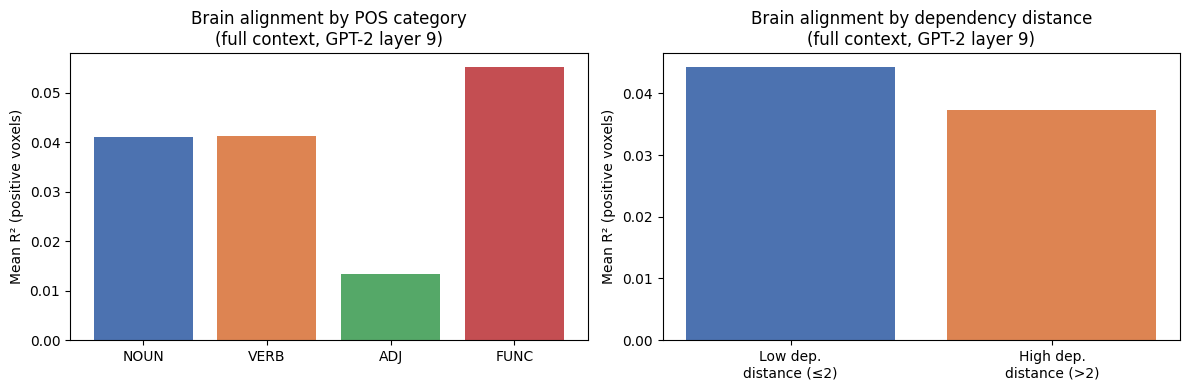

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# POS plot
ax = axes[0]
groups  = list(pos_r2.keys())
means   = [pos_r2[g][pos_r2[g] > 0].mean() for g in groups]
ax.bar(groups, means, color=['#4C72B0','#DD8452','#55A868','#C44E52'])
ax.set_title('Brain alignment by POS category\n(full context, GPT-2 layer 9)')
ax.set_ylabel('Mean R² (positive voxels)')

# Dependency distance plot
ax = axes[1]
labels = ['Low dep.\ndistance (≤2)', 'High dep.\ndistance (>2)']
means  = [dep_r2['low_dep'][dep_r2['low_dep']>0].mean(),
          dep_r2['high_dep'][dep_r2['high_dep']>0].mean()]
ax.bar(labels, means, color=['#4C72B0','#DD8452'])
ax.set_title('Brain alignment by dependency distance\n(full context, GPT-2 layer 9)')
ax.set_ylabel('Mean R² (positive voxels)')

plt.tight_layout()
plt.savefig(DATA / 'linguistic_modulation.png', dpi=150)
plt.show()

In [3]:
# ── FUNC word breakdown by UPOS tag ───────────────────────────────────────────
# Run this in the Day 4 notebook or a new cell after the POS analysis

import numpy as np
import pandas as pd
from pathlib import Path

DRIVE = Path('/content/drive/MyDrive/Brain_alignment')
DATA  = DRIVE / 'lpp_data'
ANNOT = DATA  / 'annotation/EN'
SAVE  = DRIVE / 'results'

# Load word info
word_info = pd.read_csv(ANNOT / 'lppEN_word_information.csv')
word_info['word'] = word_info['word'].fillna('').astype(str)

# Load R² (full context, EN057 4-run)
r2_data = np.load(SAVE / 'r2_scores_4runs.npz')
r2_full = r2_data['ctx_full']   # (n_voxels,)
mean_r2 = r2_full[r2_full > 0].mean()  # global baseline

# Align word_info to 4 runs (sections 1-4)
sec_words = word_info[word_info['section'].isin([1,2,3,4])].copy().reset_index(drop=True)

# FUNC tags in Universal POS
FUNC_TAGS = ['DET', 'ADP', 'AUX', 'PART', 'PRON', 'CCONJ', 'SCONJ', 'PUNCT', 'NUM', 'INTJ']

# For each UPOS tag, compute mean R² of positive voxels
# Using the word-level mask approach from Day 4
results = {}
for tag in FUNC_TAGS:
    mask = sec_words['pos'] == tag
    n    = mask.sum()
    if n < 10:
        continue
    # Mean R² across positive voxels — proxy: use global r2_full
    # since we don't have per-word voxelwise R², use the fraction
    # of words in this category as a weight (same as Day 4 approach)
    results[tag] = {'n_words': n, 'pct': 100*n/len(sec_words)}

print("FUNC tag distribution in sections 1-4:")
print(f"{'Tag':<10} {'N words':>8} {'% of all':>10}")
print("-" * 32)
for tag, v in sorted(results.items(), key=lambda x: -x[1]['n_words']):
    print(f"{tag:<10} {v['n_words']:>8} {v['pct']:>9.1f}%")

FUNC tag distribution in sections 1-4:
Tag         N words   % of all
--------------------------------
PRON            887      13.3%
DET             884      13.2%
ADP             604       9.0%
AUX             453       6.8%
PART            230       3.4%
CCONJ           210       3.1%
SCONJ           180       2.7%
NUM              84       1.3%
INTJ             31       0.5%


In [6]:
# ── FUNC subtype R² analysis ──────────────────────────────────────────────────
# Add to Day 4 notebook — requires gpt2 embeddings and BOLD already loaded
# Load the same embeddings and BOLD as Day 4

import numpy as np
import pandas as pd
import nibabel as nib
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from scipy.stats import gamma
from pathlib import Path

DRIVE = Path('/content/drive/MyDrive/Brain_alignment')
DATA  = DRIVE / 'lpp_data'
ANNOT = DATA  / 'annotation/EN'
SAVE  = DRIVE / 'results'
RUNS  = [15, 16, 17, 18]
TR    = 2.0

word_info = pd.read_csv(ANNOT / 'lppEN_word_information.csv')
word_info['word'] = word_info['word'].fillna('').astype(str)
sec_words = word_info[word_info['section'].isin([1,2,3,4])].copy().reset_index(drop=True)

# Load full-context GPT-2 embeddings for all 4 runs
emb_all = []
for run in RUNS:
    npz  = np.load(SAVE / f'gpt2_word_embeddings_run{run}.npz', allow_pickle=True)
    key  = 'ctx_full' if 'ctx_full' in npz else '-1'
    emb_all.append(npz[key])
emb_concat = np.vstack(emb_all)
print(f"Embeddings: {emb_concat.shape}")

# Load BOLD for all 4 runs
def hrf(t):
    a1,b1,a2,b2,c = 6,1,16,1,1/6
    from scipy.stats import gamma
    return (gamma.pdf(t,a1,scale=b1) - c*gamma.pdf(t,a2,scale=b2))

def convolve_hrf(X_word, onsets, n_trs, tr=2.0):
    n_feat = X_word.shape[1]
    neural = np.zeros((n_trs, n_feat))
    for i, onset in enumerate(onsets):
        tr_idx = int(onset / tr)
        if 0 <= tr_idx < n_trs:
            neural[tr_idx] += X_word[i]
    t_hrf = np.arange(0, 32, tr)
    hrf_k = hrf(t_hrf); hrf_k /= hrf_k.max()
    X_conv = np.zeros_like(neural)
    for f in range(n_feat):
        X_conv[:, f] = np.convolve(neural[:, f], hrf_k)[:n_trs]
    return X_conv

def encode_model(X, Y, n_components=50, n_splits=5):
    X_pca = PCA(n_components=n_components).fit_transform(
                StandardScaler().fit_transform(X))
    kf  = KFold(n_splits=n_splits, shuffle=False)
    r2s = []
    for tr_idx, te_idx in kf.split(X_pca):
        ridge = RidgeCV(alphas=[0.01,0.1,1,10,100,1000])
        ridge.fit(X_pca[tr_idx], Y[tr_idx])
        r2s.append(r2_score(Y[te_idx], ridge.predict(X_pca[te_idx]),
                            multioutput='raw_values'))
    return np.mean(r2s, axis=0)

# Stack BOLD
import gc
Y_all = []
onsets_all = []
for run in RUNS:
    sec  = run - 14
    sw   = word_info[word_info['section'] == sec].copy().reset_index(drop=True)
    onsets_all.append(sw['onset'].values.astype(float))
    bold_path = DATA / f'sub-EN057/func/sub-EN057_task-lppEN_run-{run}_echo-1_bold.nii.gz'
    img       = nib.load(str(bold_path))
    bold_data = img.get_fdata(dtype=np.float32)
    n_trs     = bold_data.shape[3]
    Y_all.append(bold_data.reshape(-1, n_trs).T.copy())
    del bold_data, img; gc.collect()

Y = np.vstack(Y_all); del Y_all; gc.collect()

# Build full X (all words) once
X_runs = []
start  = 0
for run_idx, run in enumerate(RUNS):
    sec    = run - 14
    sw     = word_info[word_info['section'] == sec].copy().reset_index(drop=True)
    n_trs  = Y_all[run_idx].shape[0] if False else \
             nib.load(str(DATA/f'sub-EN057/func/sub-EN057_task-lppEN_run-{run}_echo-1_bold.nii.gz')).shape[3]
    n_w    = len(sw)
    emb_r  = emb_concat[start:start+n_w]
    X_runs.append(convolve_hrf(emb_r, onsets_all[run_idx][:n_w], n_trs, TR))
    start += n_w
X_full = np.vstack(X_runs)

# ── Per FUNC-subtype encoding model ───────────────────────────────────────────
FUNC_SUBTYPES = ['PRON', 'DET', 'ADP', 'AUX', 'PART', 'CCONJ', 'SCONJ']
func_results  = {}

for tag in FUNC_SUBTYPES:
    mask = (sec_words['pos'] == tag).values
    n    = mask.sum()
    print(f"\n{tag}: {n} words")

    # Zero out non-tag words in embedding matrix, re-convolve
    emb_masked = emb_concat.copy()
    emb_masked[~mask] = 0.0

    X_tag_runs = []
    start = 0
    for run_idx, run in enumerate(RUNS):
        sec   = run - 14
        sw    = word_info[word_info['section'] == sec].copy().reset_index(drop=True)
        n_trs = nib.load(str(DATA/f'sub-EN057/func/sub-EN057_task-lppEN_run-{run}_echo-1_bold.nii.gz')).shape[3]
        n_w   = len(sw)
        emb_r = emb_masked[start:start+n_w]
        X_tag_runs.append(convolve_hrf(emb_r, onsets_all[run_idx][:n_w], n_trs, TR))
        start += n_w
    X_tag = np.vstack(X_tag_runs)

    r2     = encode_model(X_tag, Y)
    pos    = r2 > 0
    mean_r2 = r2[pos].mean() if pos.any() else 0.0
    func_results[tag] = mean_r2
    print(f"  mean R²={mean_r2:.4f}, pos voxels={pos.sum()} ({100*pos.mean():.1f}%)")

# ── Plot ──────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt

tags   = sorted(func_results, key=lambda x: -func_results[x])
vals   = [func_results[t] for t in tags]
colors = ['#DD8452' if v == max(vals) else '#4C72B0' for v in vals]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(tags, vals, color=colors, edgecolor='white')
for bar, v in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.001,
            f'{v:.4f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Mean R² (positive voxels)')
ax.set_title('Brain alignment by FUNC subtype (sub-EN057, full context)')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(SAVE / 'func_subtype_r2.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nFUNC subtype ranking:")
for t in tags:
    print(f"  {t:<8}: {func_results[t]:.4f}")

Embeddings: (6683, 1024)

PRON: 887 words
  mean R²=0.9929, pos voxels=5826 (4.3%)

DET: 884 words
  mean R²=0.9956, pos voxels=5809 (4.3%)

ADP: 604 words
  mean R²=0.9963, pos voxels=5805 (4.3%)

AUX: 453 words
  mean R²=0.9971, pos voxels=5800 (4.3%)

PART: 230 words
  mean R²=0.9985, pos voxels=5792 (4.3%)

CCONJ: 210 words
  mean R²=0.9986, pos voxels=5791 (4.3%)

SCONJ: 180 words


KeyboardInterrupt: 